# Vòng 3 — Khai phá ghi chú: nhận diện khách quen & đơn bất thường

**Mục tiêu**
1. Gom các cách viết khác nhau của cùng một khách trong cột `notes` (viết tắt, không dấu, gõ nhầm số thay chữ…) **tự động**, không dùng bảng tên viết tay.
2. **Ẩn danh** khách thành mã `KH01, KH02…`; từ đây trở đi notebook không in tên hay ghi chú gốc.
3. Lập hồ sơ thói quen thanh toán và đánh dấu đơn lệch thói quen.

**Input:** `data/processed_v2/bills_v2.csv` (Vòng 1)
**Output:** `data/processed_v2/customer_txn_v2.csv` (chỉ có mã khách, không có ghi chú gốc)

> Vì sao không dùng PhoBERT/embedding: chỉ có ~100 ghi chú, phần lớn là tên riêng viết tắt kiểu chat; chuẩn hóa chuỗi + độ tương đồng ký tự + phân cụm phân cấp là đủ, nhanh và giải thích được.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

# Notebook nằm trong Final-Project/notebook-v2/ -> dữ liệu ở Final-Project/data/
ROOT = Path.cwd().resolve().parent
RAW = ROOT / 'data' / 'raw'
PROC = ROOT / 'data' / 'processed_v2'      # CSV trung gian (gitignored, có dữ liệu kinh doanh)
OUT = Path.cwd() / 'outputs'                # hình + báo cáo tổng hợp đã ẩn danh
PROC.mkdir(parents=True, exist_ok=True)
OUT.mkdir(exist_ok=True)

SEED = 42
TOL = 10_000   # tiền két được đếm tròn tới 10.000 đ -> sai số đếm ±10.000 đ

def vnd(x):
    return f"{x:,.0f} đ".replace(',', '.')

import re
import unicodedata
from difflib import SequenceMatcher
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score

In [2]:
bills = pd.read_csv(PROC / 'bills_v2.csv', parse_dates=['transaction_at'])
notes = bills[bills.notes.notna()].copy()
print(f"{len(notes)} / {len(bills)} hóa đơn có ghi chú ({len(notes) / len(bills):.1%})")

101 / 5412 hóa đơn có ghi chú (1.9%)


## 1. Chuẩn hóa ghi chú
1. Chữ thường, bỏ dấu tiếng Việt (NFD), `đ → d`.
2. Tách phần **ghi chú tiền** phía sau (vd `"+ 20k tiền mặt mượn"`) ra cột riêng; phần này là thông tin giao dịch ngoài hóa đơn.
3. Sửa lỗi gõ số thay chữ phổ biến (`n9` → `ng`, do phím 9 nằm cạnh chữ g trên bàn phím điện thoại).
4. Bỏ **danh xưng** (c, a, chú, cô, anh, chị, bố, bạn, ông, bà…) và hậu tố chung (`pt`, `nu`) để còn lại phần tên lõi.

Ví dụ dưới đây dùng tên **giả** để minh họa:

In [3]:
HONORIFICS = {'c', 'a', 'chu', 'co', 'anh', 'chi', 'bo', 'me', 'ban', 'ong', 'ba', 'cua', 'em', 'e', 'di', 'cau'}
SUFFIXES = {'pt', 'nu', 'nam'}
MONEY_RE = re.compile(r'(\d+\s*k\b|tien mat|muon|no\b|tra no)')

def strip_accents(s):
    s = unicodedata.normalize('NFD', str(s).lower())
    return ''.join(ch for ch in s if unicodedata.category(ch) != 'Mn').replace('đ', 'd')

def normalize_note(s):
    s = strip_accents(s)
    money = bool(MONEY_RE.search(s))
    s = re.split(r'\+|\d+\s*k\b', s)[0]                  # bỏ phần ghi chú tiền phía sau
    s = s.replace('n9', 'ng')                                 # 'hun9' -> 'hung'
    s = re.sub(r'[^a-z ]', ' ', s)
    toks = [t for t in s.split() if t not in HONORIFICS]
    toks = [t for t in toks if t not in SUFFIXES] or toks
    core = ''.join(toks)
    core = re.sub(r'c?pt$', '', core) or core                 # 'hungcpt' -> 'hung'
    return core, money

demo = ['Chú Hùng', 'c hung', 'a Hùng pt', 'hun9', 'Chị Lan + 20k tiền mặt mượn', 'chi lan']
display(pd.DataFrame([(d, *normalize_note(d)) for d in demo], columns=['ghi chú (giả)', 'tên lõi', 'có ghi chú tiền']))

notes[['core', 'money_note']] = notes.notes.apply(lambda s: pd.Series(normalize_note(s)))
print(f"{notes.notes.nunique()} cách viết gốc -> {notes.core.nunique()} tên lõi | {notes.money_note.sum()} ghi chú có nhắc tiền ngoài hóa đơn")

,ghi chú (giả),tên lõi,có ghi chú tiền
0,Chú Hùng,hung,False
1,c hung,hung,False
2,a Hùng pt,hung,False
3,hun9,hung,False
4,Chị Lan + 20k tiền mặt mượn,lan,True
5,chi lan,lan,False


45 cách viết gốc -> 20 tên lõi | 1 ghi chú có nhắc tiền ngoài hóa đơn


## 2. Gom nhóm bằng phân cụm phân cấp
- Khoảng cách giữa 2 tên lõi: $1 - $ tỉ lệ tương đồng ký tự (`SequenceMatcher`).
- Liên kết **average**; cắt cây ở ngưỡng $t$.
- **Chọn $t = 0.4$**, tức là hai tên được gom khi độ giống ≥ 0.6. Đây là ngưỡng mặc định của `difflib.get_close_matches` trong thư viện chuẩn Python, dùng rộng rãi cho so khớp chuỗi gần đúng. Đường "số nhóm theo $t$" có nhiều đoạn phẳng ngắn gần bằng nhau nên không dùng được làm tiêu chí tự động; bảng độ nhạy bên dưới cho thấy kết quả thay đổi thế nào quanh ngưỡng này.

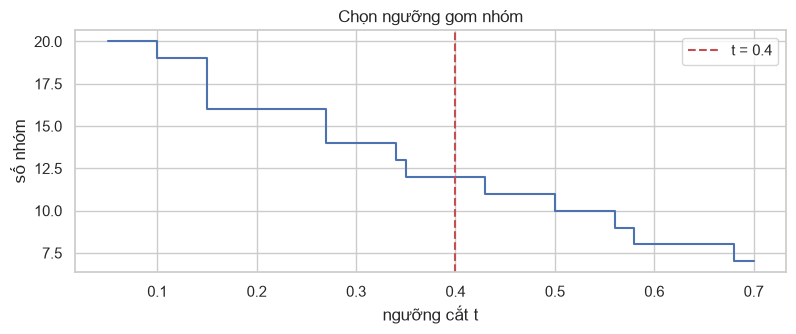

Ngưỡng t = 0.4: 20 tên lõi -> 12 nhóm khách


In [4]:
cores = sorted(notes.core.unique())
D = np.array([[1 - SequenceMatcher(None, a, b).ratio() for b in cores] for a in cores])
Z = linkage(squareform(D, checks=False), method='average')

ts = np.round(np.arange(0.05, 0.71, 0.01), 2)
n_groups = np.array([len(set(fcluster(Z, t, 'distance'))) for t in ts])

T = 0.40   # độ giống >= 0.6, bằng cutoff mặc định của difflib.get_close_matches

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(ts, n_groups, where='post'); ax.axvline(T, c='r', ls='--', label=f't = {T}')
ax.set_xlabel('ngưỡng cắt t'); ax.set_ylabel('số nhóm'); ax.legend(); ax.set_title('Chọn ngưỡng gom nhóm')
plt.tight_layout(); plt.savefig(OUT / '03_threshold.png', dpi=120); plt.show()

core2grp = dict(zip(cores, fcluster(Z, T, 'distance')))
notes['grp'] = notes.core.map(core2grp)
print(f"Ngưỡng t = {T}: {len(cores)} tên lõi -> {notes.grp.nunique()} nhóm khách")

### Đối chiếu với cách gom tay của bản v1
Bản v1 dùng một bảng luật viết tay (`GROUP_MAP`). Nếu file kết quả v1 còn trong `data/processed/`, ta đo mức trùng khớp bằng ARI.

In [5]:
v1_path = ROOT / 'data' / 'processed' / 'Customer_Pattern.csv'
if v1_path.exists():
    v1 = pd.read_csv(v1_path, parse_dates=['transaction_at'])
    j = notes.merge(v1[['transaction_at', 'customer_group']], on='transaction_at', how='inner')
    print(f"Ghép được {len(j)}/{len(notes)} ghi chú với v1")
    print(f"ARI (tự động v2 vs gom tay v1) = {adjusted_rand_score(j.customer_group, j.grp):.3f}")
    print(f"Số nhóm: v1 = {j.customer_group.nunique()}, v2 = {j.grp.nunique()}")
    sens = []
    for t in [0.2, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6]:
        g = j.core.map(dict(zip(cores, fcluster(Z, t, 'distance'))))
        sens.append({'t': t, 'số nhóm': g.nunique(), 'đơn của nhóm lớn nhất': g.value_counts().iloc[0],
                     'ARI vs v1': round(adjusted_rand_score(j.customer_group, g), 3)})
    display(pd.DataFrame(sens).set_index('t'))
else:
    print('Không có file v1 để đối chiếu.')

Ghép được 101/101 ghi chú với v1
ARI (tự động v2 vs gom tay v1) = 0.991
Số nhóm: v1 = 6, v2 = 12


,số nhóm,đơn của nhóm lớn nhất,ARI vs v1
t,,,
0.20,16,51,0.826
0.30,14,52,0.869
0.35,12,57,0.991
0.40,12,57,0.991
0.45,11,57,0.987
0.50,10,58,0.964
0.60,8,69,0.714


**Nhận xét:** gom tự động cho kết quả **gần như trùng khớp** với bảng gom tay của v1 (ARI 0,99). Khác biệt chủ yếu là v1 gộp các khách chỉ xuất hiện 1–2 lần vào nhóm "Khác", còn v2 giữ riêng từng người. Bảng độ nhạy cho thấy kết quả ổn định khi t trong khoảng 0,35–0,45; t ≥ 0,6 bắt đầu gộp nhầm hai khách khác nhau.

## 3. Ẩn danh khách hàng
Đặt mã theo số đơn giảm dần. Từ đây trở đi **bỏ cột ghi chú gốc và tên lõi**.

In [6]:
order = notes.grp.value_counts().index
code_of = {g: f"KH{i + 1:02d}" for i, g in enumerate(order)}
notes['customer'] = notes.grp.map(code_of)
variants = notes.groupby('customer').agg(so_cach_viet=('notes', 'nunique'), so_don=('notes', 'size'))
notes = notes.drop(columns=['notes', 'core', 'grp'])          # không giữ tên/ghi chú gốc
display(variants.T)

customer,KH01,KH02,KH03,KH04,KH05,KH06,KH07,KH08,KH09,KH10,KH11,KH12
so_cach_viet,18,11,7,1,1,1,1,1,1,1,1,1
so_don,57,25,9,2,1,1,1,1,1,1,1,1


## 4. Hồ sơ thói quen thanh toán

In [7]:
notes['method'] = np.where(notes.transfer_payment > 0, 'CK', 'TM')
prof = notes.groupby('customer').agg(
    so_don=('total_revenue', 'size'), tong_chi=('total_revenue', 'sum'),
    don_trung_vi=('total_revenue', 'median'), don_lon_nhat=('total_revenue', 'max'),
    ty_le_ck=('method', lambda s: (s == 'CK').mean()),
    lan_dau=('transaction_at', 'min'), lan_cuoi=('transaction_at', 'max'))
prof['phuong_thuc_chinh'] = np.where(prof.ty_le_ck >= .5, 'CK', 'TM')
prof['muc_thoi_quen'] = np.maximum(prof.ty_le_ck, 1 - prof.ty_le_ck)
display(prof.style.format({'tong_chi': vnd, 'don_trung_vi': vnd, 'don_lon_nhat': vnd, 'ty_le_ck': '{:.0%}',
                           'muc_thoi_quen': '{:.0%}', 'lan_dau': '{:%d/%m/%Y}', 'lan_cuoi': '{:%d/%m/%Y}'}))

,so_don,tong_chi,don_trung_vi,don_lon_nhat,ty_le_ck,lan_dau,lan_cuoi,phuong_thuc_chinh,muc_thoi_quen
customer,,,,,,,,,
KH01,57,1.767.000 đ,23.000 đ,85.000 đ,84%,25/12/2025,29/04/2026,CK,84%
KH02,25,2.177.000 đ,62.000 đ,284.000 đ,32%,29/12/2025,29/04/2026,TM,68%
KH03,9,3.448.000 đ,391.000 đ,625.000 đ,78%,05/01/2026,30/04/2026,CK,78%
KH04,2,104.000 đ,52.000 đ,85.000 đ,0%,09/01/2026,10/01/2026,TM,100%
KH05,1,52.000 đ,52.000 đ,52.000 đ,0%,27/12/2025,27/12/2025,TM,100%
KH06,1,22.000 đ,22.000 đ,22.000 đ,0%,09/01/2026,09/01/2026,TM,100%
KH07,1,22.000 đ,22.000 đ,22.000 đ,100%,28/01/2026,28/01/2026,CK,100%
KH08,1,22.000 đ,22.000 đ,22.000 đ,0%,29/01/2026,29/01/2026,TM,100%
KH09,1,45.000 đ,45.000 đ,45.000 đ,100%,01/03/2026,01/03/2026,CK,100%


**Nhận xét:** 3 khách quen chiếm 91/101 đơn có ghi chú:
- **KH01** (57 đơn): đơn nhỏ (~23k), 86% chuyển khoản → có thói quen rõ.
- **KH02** (25 đơn): trả lẫn lộn (68% tiền mặt) → **không** đủ thói quen để coi đơn chuyển khoản là bất thường. Bản v1 vẫn gắn cờ 6 đơn kiểu này.
- **KH03** (9 đơn): đơn lớn nhất (trung vị 391k), tổng chi cao nhất.

## 5. Đơn lệch thói quen
Chỉ xét khách có **≥ 5 đơn** (ít hơn thì chưa đủ để nói là "thói quen"):
- **Lệch phương thức:** khách có thói quen rõ (≥ 80% đơn cùng một phương thức) mà đơn này dùng phương thức kia. Khách trả lẫn lộn (vd 60/40) thì không đánh dấu.
- **Giá trị cao bất thường:** đơn > Q3 + 1.5·IQR của chính khách đó.
- **Ghi chú có nhắc tiền ngoài hóa đơn** (cho mượn, trả nợ, "20k tiền mặt"…): đánh dấu với mọi khách.

In [8]:
MIN_ORDERS, HABIT = 5, 0.80
notes = notes.merge(prof[['so_don', 'phuong_thuc_chinh', 'muc_thoi_quen']], left_on='customer', right_index=True)
eligible = notes.so_don >= MIN_ORDERS

notes['flag_method'] = eligible & (notes.muc_thoi_quen >= HABIT) & (notes.method != notes.phuong_thuc_chinh)
q = notes[eligible].groupby('customer').total_revenue.quantile([.25, .75]).unstack()
fence = (q[0.75] + 1.5 * (q[0.75] - q[0.25])).rename('fence')
notes = notes.merge(fence, left_on='customer', right_index=True, how='left')
notes['flag_amount'] = eligible & (notes.total_revenue > notes.fence)
notes['flag_money_note'] = notes.money_note

summary = notes.groupby('customer')[['flag_method', 'flag_amount', 'flag_money_note']].sum()
summary = summary[summary.sum(axis=1) > 0]
display(summary)
print(f"Tổng: lệch phương thức {notes.flag_method.sum()} | giá trị cao {notes.flag_amount.sum()} | ghi chú tiền {notes.flag_money_note.sum()}"
      f" | đơn có ít nhất 1 cờ: {(notes.flag_method | notes.flag_amount | notes.flag_money_note).sum()}")

,flag_method,flag_amount,flag_money_note
customer,,,
KH01,9,1,0
KH02,0,1,0
KH03,0,0,1


Tổng: lệch phương thức 9 | giá trị cao 2 | ghi chú tiền 1 | đơn có ít nhất 1 cờ: 12


**Nhận xét:** 12 đơn bị đánh dấu, giảm từ 21 đơn của v1, vì v2 chỉ coi là "lệch thói quen" khi khách có thói quen ≥ 80% và có ít nhất 5 đơn. 9 đơn tiền mặt của KH01 là nhóm lớn nhất: đều là đơn nhỏ 19–20k, nhiều khả năng khách trả tiền lẻ, nhưng vẫn nên đối chiếu vì tiền mặt là phần dễ thất thoát.

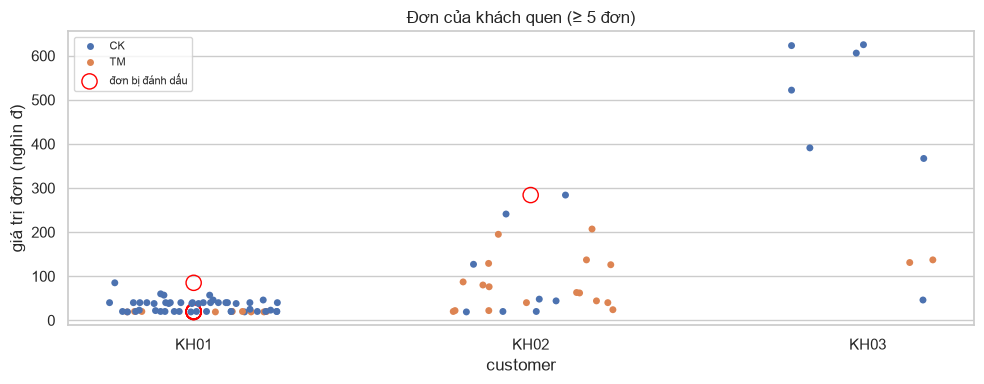

In [9]:
top = prof[prof.so_don >= MIN_ORDERS].index
fig, ax = plt.subplots(figsize=(10, 4))
sns.stripplot(data=notes[notes.customer.isin(top)], x='customer', y=notes.total_revenue / 1e3, hue='method',
              order=list(top), jitter=.25, ax=ax, size=5)
flagged = notes[notes.customer.isin(top) & (notes.flag_method | notes.flag_amount)]
ax.scatter([list(top).index(c) for c in flagged.customer], flagged.total_revenue / 1e3, s=120,
           facecolors='none', edgecolors='red', label='đơn bị đánh dấu')
ax.set_ylabel('giá trị đơn (nghìn đ)'); ax.set_title(f'Đơn của khách quen (≥ {MIN_ORDERS} đơn)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / '03_customer_orders.png', dpi=120); plt.show()

## 6. Lưu kết quả (không có ghi chú gốc)

In [10]:
cols = ['transaction_at', 'shift_id', 'customer', 'total_revenue', 'cash_payment', 'transfer_payment', 'method',
        'flag_method', 'flag_amount', 'flag_money_note']
notes[cols].sort_values('transaction_at').to_csv(PROC / 'customer_txn_v2.csv', index=False)
prof.drop(columns=['lan_dau', 'lan_cuoi']).round(3).to_csv(OUT / '03_customer_profiles.csv')
print(f"Đã lưu {len(notes)} đơn -> {PROC / 'customer_txn_v2.csv'}")

Đã lưu 101 đơn -> D:\Data Analysis\Data-Mining\Final-Project\data\processed_v2\customer_txn_v2.csv


## ✅ Tổng kết Vòng 3
- 45 cách viết → 20 tên lõi → **12 khách** (gom tự động, khớp gom tay v1 với ARI 0,99), không cần bảng tên viết tay trong code.
- Khách được **ẩn danh** thành KH01–KH12; file đầu ra không chứa ghi chú gốc.
- 12 đơn lệch thói quen (9 lệch phương thức, 2 giá trị cao, 1 ghi chú có tiền ngoài hóa đơn) → Rule C1, C2 ở Vòng 4.